<a href="https://colab.research.google.com/github/EthanJF-Physics/MAT422/blob/main/MAT422HW8EthanF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import math as math

### 3.3.1 Necessary and Sufficient Conditions of Local Minimizers

The goal is to solve the unconstrained optimization problem

$$
\min_{x\in\mathbb{R}^d} f(x).
$$

**Definition 3.3.1 (Global Minimizer).** Let $f:\mathbb{R}^d\to\mathbb{R}$ be a real-valued function. The point $x^*\in\mathbb{R}^d$ is a global minimizer of $f$ if

$$
f(x)\geq f(x^*),\qquad \forall x\in\mathbb{R}^d.
$$

**Definition 3.3.2 (Local Minimizer).** Let $f:\mathbb{R}^d\to\mathbb{R}$ be a real-valued function. The point $x^*\in\mathbb{R}^d$ is a local minimizer of $f$ if there exists a $\delta>0$ such that

$$
f(x)\geq f(x^*),\qquad \forall x\in B_\delta(x^*).
$$

**Definition 3.3.3 (Descent Direction).** Let $f:\mathbb{R}^d\to\mathbb{R}$ be a real-valued function. A vector $v\in\mathbb{R}^d$ is a descent direction for $f$ at $x_0\in\mathbb{R}^d$ if there exists an $\alpha^*>0$ such that

$$
f(x_0+\alpha v)<f(x_0),\qquad \forall \alpha\in(0,\alpha^*).
$$

In the continuously differentiable case, the directional derivative provides a criterion for identifying descent directions.

**Lemma 3.3.4 (Descent Direction and Directional Derivative).** Let $f:\mathbb{R}^d\to\mathbb{R}$ be continuously differentiable at $x_0\in\mathbb{R}^d$. If $v\in\mathbb{R}^d$ satisfies

$$
\frac{\partial f(x_0)}{\partial v}
=\nabla f(x_0)^T v<0,
\tag{3.3.5}
$$

then $v$ is a descent direction for $f$ at $x_0$.

**Theorem 3.3.6 (First-Order Necessary Condition).** Let $f:\mathbb{R}^d\to\mathbb{R}$ be continuously differentiable on $\mathbb{R}^d$. If $x_0\in\mathbb{R}^d$ is a local minimizer of $f$, then

$$
\nabla f(x_0)=0.
$$

If $f$ is twice continuously differentiable, the Hessian matrix provides a second-order necessary condition for local minimizers.

**Definition 3.3.7 (Positive Semidefinite Matrix).** A symmetric matrix $H\in\mathbb{R}^{d\times d}$ is positive semidefinite (PSD) if

$$
x^T Hx\geq 0,\qquad \forall x\in\mathbb{R}^d.
$$

**Theorem 3.3.8 (Second-Order Necessary Condition).** Let $f:\mathbb{R}^d\to\mathbb{R}$ be twice continuously differentiable on $\mathbb{R}^d$. If $x_0\in\mathbb{R}^d$ is a local minimizer of $f$, then the Hessian matrix $\nabla^2 f(x_0)$ is positive semidefinite.

In [9]:
# Section 3.3.1: Necessary Conditions for Local Minimizers
# Example function: f(x) = (x - 3)^2
def f(x):
    return (x - 3)**2
def grad_f(x):
    return 2 * (x - 3)
def hessian_f(x):
    return np.array([[2.0]])
# Lemma 3.3.4: Descent direction
def descent_direction(x):
    return -grad_f(x)
# Theorem 3.3.6: First-order necessary condition
def check_first_order(x, tol=1e-6):
    passed = abs(grad_f(x)) < tol
    print("First-order condition:", "PASS" if passed else "FAIL")
    return passed
# Theorem 3.3.8: Second-order necessary condition
def check_second_order(x, tol=1e-10):
    H = hessian_f(x)
    eigenvalues = np.linalg.eigvalsh(H)
    passed = np.all(eigenvalues >= -tol)
    print("Second-order condition (Hessian PSD):",
          "PASS" if passed else "FAIL")
    return passed
# Test at the minimizer x = 3
x0 = 3.0
print("Function value:", f(x0))
print("Gradient:", grad_f(x0))
print("Descent direction:", descent_direction(x0))

check_first_order(x0)
check_second_order(x0)

Function value: 0.0
Gradient: 0.0
Descent direction: -0.0
First-order condition: PASS
Second-order condition (Hessian PSD): PASS


np.True_

### 3.3.1.1 Sufficient Conditions for Local Minimizers

**Theorem 3.3.10 (Second-Order Sufficient Condition).** Let $f:\mathbb{R}^d\to\mathbb{R}$ be twice continuously differentiable on $\mathbb{R}^d$. If $x_0\in\mathbb{R}^d$ satisfies

$$
\nabla f(x_0)=0
$$

and the Hessian matrix $H_f(x_0)=\nabla^2 f(x_0)$ is positive definite, then $x_0$ is a strict local minimizer of $f$.

In [10]:
# Section 3.3.1.1: Second-Order Sufficient Condition
import numpy as np
def check_sufficient_condition(name, gradient, hessian, x):
    H = np.array([[hessian(x)]])
    print(f"\n{name}")
    if not np.isclose(gradient(x), 0):
        print("FAIL: Gradient is not zero.")
        return False
    if np.all(np.linalg.eigvalsh(H) > 1e-10):
        print("PASS: Strict local minimum guaranteed.")
        return True
    print("FAIL: Hessian is not positive definite.")
    return False

# Example 1: PASS — f(x) = (x - 3)^2
check_sufficient_condition(
    "Example 1: Quadratic",
    lambda x: 2 * (x - 3),
    lambda x: 2,
    3.0
)
# Example 2: FAIL — f(x) = (x - 3)^3
check_sufficient_condition(
    "Example 2: Cubic",
    lambda x: 3 * (x - 3)**2,
    lambda x: 6 * (x - 3),
    3.0
)


Example 1: Quadratic
PASS: Strict local minimum guaranteed.

Example 2: Cubic
FAIL: Hessian is not positive definite.


False

### 3.3.2 Convexity and Global Minimizers

A real-valued function is called convex if the line segment between any two points on the graph of the function lies above the graph between the two points. Our optimality conditions have only concerned local minimizers. Indeed, in the absence of global structure, local information such as gradients and Hessians can only inform about the immediate neighborhood of points. Here, we consider convexity, under which local minimizers are also global minimizers.

### 3.3.2.1 Convex Sets and Functions

**Definition 3.3.11 (Convex Set).** A set $D\subseteq\mathbb{R}^d$ is convex if, for all $x,y\in D$ and all $\alpha\in[0,1]$,

$$
(1-\alpha)x+\alpha y\in D.
$$

**Definition 3.3.13 (Convex Function).** A function $f:\mathbb{R}^d\to\mathbb{R}$ is convex if, for all $x,y\in\mathbb{R}^d$ and all $\alpha\in[0,1]$,

$$
f((1-\alpha)x+\alpha y)
\leq (1-\alpha)f(x)+\alpha f(y).
\tag{3.3.7}
$$

More generally, a function $f:D\to\mathbb{R}$ over a convex domain $D\subseteq\mathbb{R}^d$ is convex if the definition above holds for all $x,y\in D$ and $\alpha\in[0,1]$.

**Lemma 3.3.14 (Affine Functions Are Convex).** Let $w\in\mathbb{R}^d$ and $b\in\mathbb{R}$. The function $f(x)=w^T x+b$ is convex.

**Lemma 3.3.15 (First-Order Convexity Condition).** Let $f:\mathbb{R}^d\to\mathbb{R}$ be continuously differentiable. Then $f$ is convex if and only if, for all $x,y\in\mathbb{R}^d$,

$$
f(y)\geq f(x)+\nabla f(x)^T(y-x).
\tag{3.3.8}
$$

**Lemma 3.3.16 (Second-Order Convexity Condition).** Let $f:\mathbb{R}^d\to\mathbb{R}$ be twice continuously differentiable. Then $f$ is convex if and only if, for all $x\in\mathbb{R}^d$, the Hessian matrix $H_f(x)=\nabla^2 f(x)$ is positive semidefinite.

First-order convexity: PASS (sampled points)
Second-order convexity: PASS


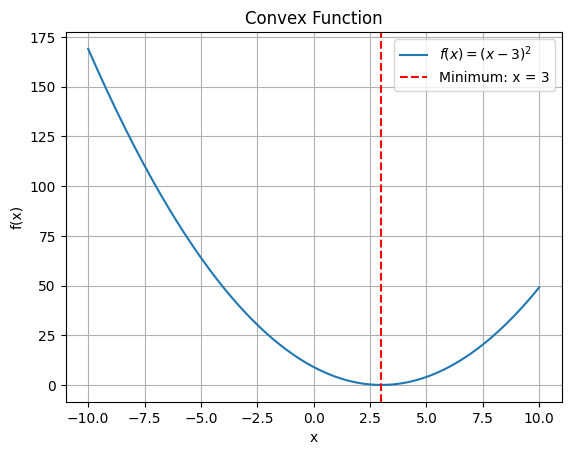

In [11]:
# Section 3.3.2: Convexity and Global Minimizers
# Example function: f(x) = (x - 3)^2
def f(x):
    return (x - 3)**2
def grad_f(x):
    return 2 * (x - 3)
def hessian_f(x):
    return 2.0
# Lemma 3.3.15: First-order convexity condition
def check_first_order_convexity(func, gradient, points):
    for x in points:
        for y in points:
            lower_bound = func(x) + gradient(x) * (y - x)
            if func(y) < lower_bound - 1e-10:
                print("First-order convexity: FAIL")
                return False

    print("First-order convexity: PASS (sampled points)")
    return True
# Lemma 3.3.16: Second-order convexity condition
def check_second_order_convexity(hessian, points):
    passed = all(hessian(x) >= -1e-10 for x in points)
    print("Second-order convexity:", "PASS" if passed else "FAIL")
    return passed

# Run checks
x_values = np.linspace(-10, 10, 100)
check_first_order_convexity(f, grad_f, x_values)
check_second_order_convexity(hessian_f, x_values)
# Plot the convex function
x = np.linspace(-10, 10, 200)
plt.plot(x, f(x), label=r"$f(x)=(x-3)^2$")
plt.axvline(3, color="red", linestyle="--", label="Minimum: x = 3")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Convex Function")
plt.legend()
plt.grid(True)
plt.show()

### 3.3.2.2 Global Minimizers of Convex Functions

For a convex function, the first-order condition $\nabla f(x_0)=0$ is sufficient to guarantee that $x_0$ is a global minimizer. Thus, convexity allows us to establish global optimality using local information.

**Theorem 3.3.18 (Global Minimizer Condition).** Let $f:\mathbb{R}^d\to\mathbb{R}$ be a continuously differentiable, convex function. If $x_0\in\mathbb{R}^d$ satisfies

$$
\nabla f(x_0)=0,
$$

then $x_0$ is a global minimizer of $f$.

**Theorem 3.3.19 (Global Minimizers of Convex Functions).** Let $f:\mathbb{R}^d\to\mathbb{R}$ be a convex function. Then any local minimizer of $f$ is also a global minimizer.

In [12]:
# Section 3.3.2.2: Global Minimizers of Convex Functions
# Example: f(x) = (x - 3)^2
def f(x):
    return (x - 3)**2
def grad_f(x):
    return 2 * (x - 3)
def hessian_f(x):
    return 2.0

# Theorem 3.3.18: Zero gradient + convexity => global minimizer
def check_global_minimizer(x):
    if np.isclose(grad_f(x), 0) and hessian_f(x) >= 0:
        print(f"PASS: x = {x} is a global minimizer.")
        print(f"f(x) = {f(x)}")
        return True

    print("FAIL: Global minimum not established.")
    return False

# Theorem 3.3.19: Local minimizer of a convex function is global
def check_local_to_global(x):
    is_local_minimum = np.isclose(grad_f(x), 0)
    is_convex = hessian_f(x) >= 0
    if is_local_minimum and is_convex:
        print("PASS: The local minimizer is also a global minimizer.")
        return True
    print("FAIL: Conditions not established.")
    return False

# Run both theorem checks
x0 = 3.0
check_global_minimizer(x0)
check_local_to_global(x0)

PASS: x = 3.0 is a global minimizer.
f(x) = 0.0
PASS: The local minimizer is also a global minimizer.


True

### 3.3.3 Gradient Descent

Gradient descent is an iterative optimization algorithm for finding a local minimum of a differentiable function. The method iteratively updates the current point by moving in a direction that decreases the function value.

### 3.3.3.1 Steepest Descent

The steepest descent approach seeks to decrease the value of $f$ by successively following directions of maximal decrease.

**Lemma 3.3.22 (Steepest Descent).** Let $f:\mathbb{R}^d\to\mathbb{R}$ be continuously differentiable at $x_0$. For any unit vector $v\in\mathbb{R}^d$,

$$
\frac{\partial f(x_0)}{\partial v}
\geq
\frac{\partial f(x_0)}{\partial v^*},
\tag{3.3.10}
$$

where

$$
v^*=-\frac{\nabla f(x_0)}{\|\nabla f(x_0)\|}.
\tag{3.3.11}
$$

Thus, the negative normalized gradient gives the direction of steepest descent when $\nabla f(x_0)\neq 0$.

**Theorem 3.3.23 (Monotonicity of Steepest Descent).** Suppose that $f:\mathbb{R}^d\to\mathbb{R}$ is twice continuously differentiable. At each iteration, choose the step size by exact line search:

$$
\alpha_k=\arg\min_{\alpha>0}
f\bigl(x_k-\alpha\nabla f(x_k)\bigr).
$$

The steepest descent method generates a sequence $\{x_k\}_{k=0}^{\infty}$ according to

$$
x_{k+1}=x_k-\alpha_k\nabla f(x_k).
$$

If the line-search minimizer exists, then the function values are nonincreasing. In particular, if $\nabla f(x_k)\neq 0$, then

$$
f(x_{k+1})\leq f(x_k),
\qquad \forall k\geq 0.
$$

Steepest descent direction at x = 0: 1.0
Approximate minimizer: 2.9999571825692186
Minimum function value: 1.8333323787185533e-09
Function values nonincreasing: True


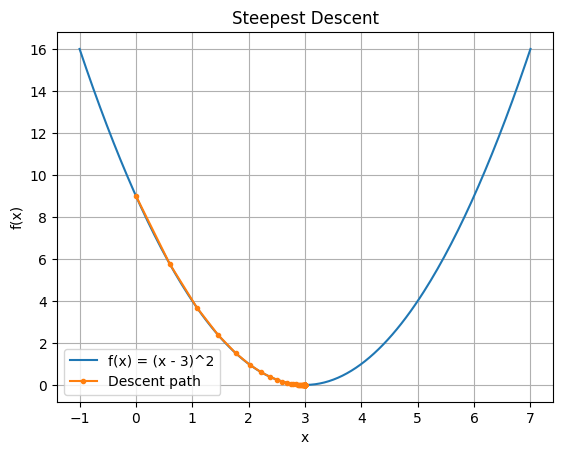

In [13]:
# Section 3.3.3: Gradient Descent and Steepest Descent
# Example: f(x) = (x - 3)^2
def f(x):
    return (x - 3)**2
def grad_f(x):
    return 2 * (x - 3)

# Lemma 3.3.22: Steepest descent direction
def steepest_direction(x):
    gradient = grad_f(x)
    if np.isclose(gradient, 0):
        return 0.0
    return -gradient / abs(gradient)  # Unit direction in 1D

# Gradient descent algorithm
def gradient_descent(x0, learning_rate=0.1, iterations=50):
    x = float(x0)
    history = [x]

    for _ in range(iterations):
        x -= learning_rate * grad_f(x)
        history.append(x)

    return history

# Theorem 3.3.23: Check monotonicity
def check_monotonicity(history):
    values = [f(x) for x in history]
    passed = all(a >= b - 1e-12 for a, b in zip(values, values[1:]))
    print("Function values nonincreasing:", passed)
    return passed

# Run example
x0 = 0.0
print("Steepest descent direction at x = 0:", steepest_direction(x0))

history = gradient_descent(x0)
print("Approximate minimizer:", history[-1])
print("Minimum function value:", f(history[-1]))
check_monotonicity(history)

# Plot function and descent path
x = np.linspace(-1, 7, 200)
plt.plot(x, f(x), label="f(x) = (x - 3)^2")
plt.plot(history, [f(v) for v in history], "o-",
         markersize=3, label="Descent path")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Steepest Descent")
plt.legend()
plt.grid(True)
plt.show()